# Повышение разрешения изображений (Single Image Super-Resolution)
**Архитектура: SRGAN (Super-Resolution Generative Adversarial Network)**

Данный блокнот реализует задачу повышения разрешения изображений (Super-Resolution, SR) с коэффициентом увеличения **4x**.

**Проблема:** Традиционные методы, минимизирующие среднеквадратичную ошибку (MSE), дают высокий показатель PSNR, но приводят к "замыленным" изображениям, лишенным высокочастотных деталей (текстур).

**Решение:** Используем генеративно-состязательную сеть (GAN) из статьи *Ledig et al., 2017*. Генератор учится создавать фотореалистичные текстуры, а Дискриминатор заставляет его делать изображения неотличимыми от оригинальных. Для сохранения контента используется Перцептивная потеря (Perceptual Loss) на основе предобученной сети VGG19.

*Примечание для быстрой демонстрации: используем подвыборку датасета (10 000 лиц) и обучаем 10 эпох, чтобы уложиться в лимиты времени Google Colab.*

In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision.datasets import CelebA
from torchvision.models import vgg19, VGG19_Weights
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm

# Настройка устройства (GPU в Colab)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

# Гиперпараметры
BATCH_SIZE = 16
EPOCHS = 10
LR = 1e-4
IMAGE_SIZE = 128
SCALE_FACTOR = 4
LR_SIZE = IMAGE_SIZE // SCALE_FACTOR

Используемое устройство: cuda


## 1. Подготовка данных
Загружаем датасет **CelebA**.
Модель обучается на парах изображений:
* **HR (High-Resolution):** Оригинальное изображение 128x128 пикселей.
* **LR (Low-Resolution):** Уменьшенная копия 32x32 пикселя (с помощью `transforms.functional.resize`).

Задача сети — научиться восстанавливать из картинки 32x32 исходное качество 128x128.

In [ ]:
transform_hr = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

class SRDataset(Dataset):
    def __init__(self, root, split='train', download=False):
        self.dataset = CelebA(root=root, split=split, download=download, transform=transform_hr)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        hr_img, _ = self.dataset[idx]
        lr_img = transforms.functional.resize(hr_img, (LR_SIZE, LR_SIZE))
        return lr_img, hr_img


print("Загрузка датасета...")
full_dataset = SRDataset(root='./data', split='train', download=True)

# Берем подвыборку из 10 000 изображений
subset_indices = list(range(10000))
train_dataset = Subset(full_dataset, subset_indices)

# DataLoader с 4 рабочими процессами
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
print(f"Размер тренировочного набора: {len(train_dataset)} изображений")

Загрузка датасета...
Размер тренировочного набора: 10000 изображений


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


## 2. Архитектура сети
### 2.1. Генератор
Генератор построен на основе глубокой остаточной сети (ResNet).
* Сначала применяется свертка 9x9.
* Затем идут **16 Residual Blocks** (блоков остаточной связи), которые позволяют обучать очень глубокие сети без затухания градиентов.
* Для увеличения разрешения в 4 раза используется **PixelShuffle** (субпиксельная свертка). Это эффективнее и качественнее, чем обычный `Upsample` или бикубическая интерполяция.
* На выходе стоит функция активации `Tanh`, так как данные нормализованы в диапазон [-1, 1].

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        self.prelu = nn.PReLU()
        self.conv2 = nn.Conv2d(channels, channels, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = self.conv1(x)
        residual = self.bn1(residual)
        residual = self.prelu(residual)
        residual = self.conv2(residual)
        residual = self.bn2(residual)
        return x + residual

class Generator(nn.Module):
    def __init__(self, scale_factor=4, num_blocks=16):
        super(Generator, self).__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=9, stride=1, padding=4)
        self.prelu = nn.PReLU()

        self.res_blocks = nn.Sequential(*[ResidualBlock(64) for _ in range(num_blocks)])

        self.conv2 = nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        upsampling = []
        for _ in range(int(np.log2(scale_factor))):
            upsampling.append(nn.Conv2d(64, 256, kernel_size=3, stride=1, padding=1))
            upsampling.append(nn.PixelShuffle(2))
            upsampling.append(nn.PReLU())
        self.upsampling = nn.Sequential(*upsampling)

        self.conv3 = nn.Conv2d(64, 3, kernel_size=9, stride=1, padding=4)
        self.tanh = nn.Tanh()

    def forward(self, x):
        out1 = self.prelu(self.conv1(x))
        out = self.res_blocks(out1)
        out = self.bn2(self.conv2(out))
        out = out + out1
        out = self.upsampling(out)
        out = self.tanh(self.conv3(out))
        return out

### 2.2. Дискриминатор
Дискриминатор — это классификатор, который пытается отличить сгенерированное изображение от реального.
Используется архитектура, похожая на VGG: серия сверточных слоев с увеличением количества каналов (64 -> 512) и уменьшением пространственного размера (stride=2).
На выходе — вероятность того, что изображение реальное (от 0 до 1).

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
            nn.Linear(512 * 4 * 4, 1024),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### 2.3. Перцептивная потеря (Perceptual Loss)
Как сказано в статье, MSE-потеря приводит к размытию. Поэтому используем **VGG Perceptual Loss**.
Пропускаем сгенерированное и оригинальное изображения через предобученную сеть VGG19 (слой `conv5_4`) и считаем разницу между *картами признаков* (feature maps). Это заставляет генератор создавать правильные текстуры и структуры, а не просто усреднять пиксели.

In [ ]:
class VGGPerceptualLoss(nn.Module):
    def __init__(self):
        super(VGGPerceptualLoss, self).__init__()
        vgg = vgg19(weights=VGG19_Weights.DEFAULT).features
        self.feature_extractor = nn.Sequential(*list(vgg.children())[:36]).eval()
        for param in self.feature_extractor.parameters():
            param.requires_grad = False

        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def forward(self, sr, hr):
        sr_vgg = (sr + 1) / 2.0
        hr_vgg = (hr + 1) / 2.0

        sr_vgg = self.normalize(sr_vgg)
        hr_vgg = self.normalize(hr_vgg)

        sr_features = self.feature_extractor(sr_vgg)
        hr_features = self.feature_extractor(hr_vgg)

        return nn.functional.mse_loss(sr_features, hr_features)

# Инициализация моделей
generator = Generator(scale_factor=SCALE_FACTOR).to(device)
discriminator = Discriminator().to(device)

optim_G = optim.Adam(generator.parameters(), lr=LR, betas=(0.9, 0.999))
optim_D = optim.Adam(discriminator.parameters(), lr=LR, betas=(0.9, 0.999))

criterion_GAN = nn.BCELoss()
criterion_perceptual = VGGPerceptualLoss().to(device)

## 3. Инициализация и обучение
В SRGAN используются две функции потерь для Генератора:
1. **Content Loss** (наша VGG Perceptual Loss).
2. **Adversarial Loss** (BCE loss).
Итоговая формула: `Loss_G = Content_Loss + 10^-3 * Adversarial_Loss`.

Дискриминатор обучается стандартным способом: отличать реальные (HR) от поддельных (SR).

In [ ]:
generator = Generator(scale_factor=SCALE_FACTOR).to(device)
discriminator = Discriminator().to(device)

optim_G = optim.Adam(generator.parameters(), lr=LR, betas=(0.9, 0.999))
optim_D = optim.Adam(discriminator.parameters(), lr=LR, betas=(0.9, 0.999))

criterion_GAN = nn.BCELoss()
criterion_perceptual = VGGPerceptualLoss().to(device)

In [ ]:
print("Начало обучения...")
for epoch in range(EPOCHS):
    loop = tqdm(train_loader, leave=True)
    for idx, (lr_imgs, hr_imgs) in enumerate(loop):
        lr_imgs = lr_imgs.to(device)
        hr_imgs = hr_imgs.to(device)

        valid = torch.ones((hr_imgs.size(0), 1), device=device, requires_grad=False)
        fake = torch.zeros((hr_imgs.size(0), 1), device=device, requires_grad=False)

        optim_G.zero_grad()
        gen_imgs = generator(lr_imgs)

        pred_fake = discriminator(gen_imgs)
        loss_GAN = criterion_GAN(pred_fake, valid)
        loss_content = criterion_perceptual(gen_imgs, hr_imgs)

        loss_G = loss_content + 1e-3 * loss_GAN

        loss_G.backward()
        optim_G.step()

        optim_D.zero_grad()

        pred_real = discriminator(hr_imgs)
        loss_real = criterion_GAN(pred_real, valid)

        pred_fake = discriminator(gen_imgs.detach())
        loss_fake = criterion_GAN(pred_fake, fake)

        loss_D = 0.5 * (loss_real + loss_fake)

        loss_D.backward()
        optim_D.step()

        loop.set_description(f"Epoch [{epoch+1}/{EPOCHS}]")
        loop.set_postfix(loss_D=loss_D.item(), loss_G=loss_G.item())

Начало обучения...


  0%|          | 0/625 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
Epoch [10/10]: 100%|██████████| 625/625 [03:41<00:00,  2.82it/s, loss_D=0.00137, loss_G=0.124]


## 4. Оценка результатов
Выведем несколько примеров (сеткой), чтобы сравнить:
1. **LR** (как выглядело исходное изображение).
2. **SRGAN** (что восстановила сеть).
3. **HR** (идеальный оригинал, к которому мы стремились).

Сравнивая SRGAN и HR, можно заметить, что сеть "додумывает" текстуры (например, поры кожи или волосы), делая изображение визуально резким, даже если попиксельно они немного отличаются.

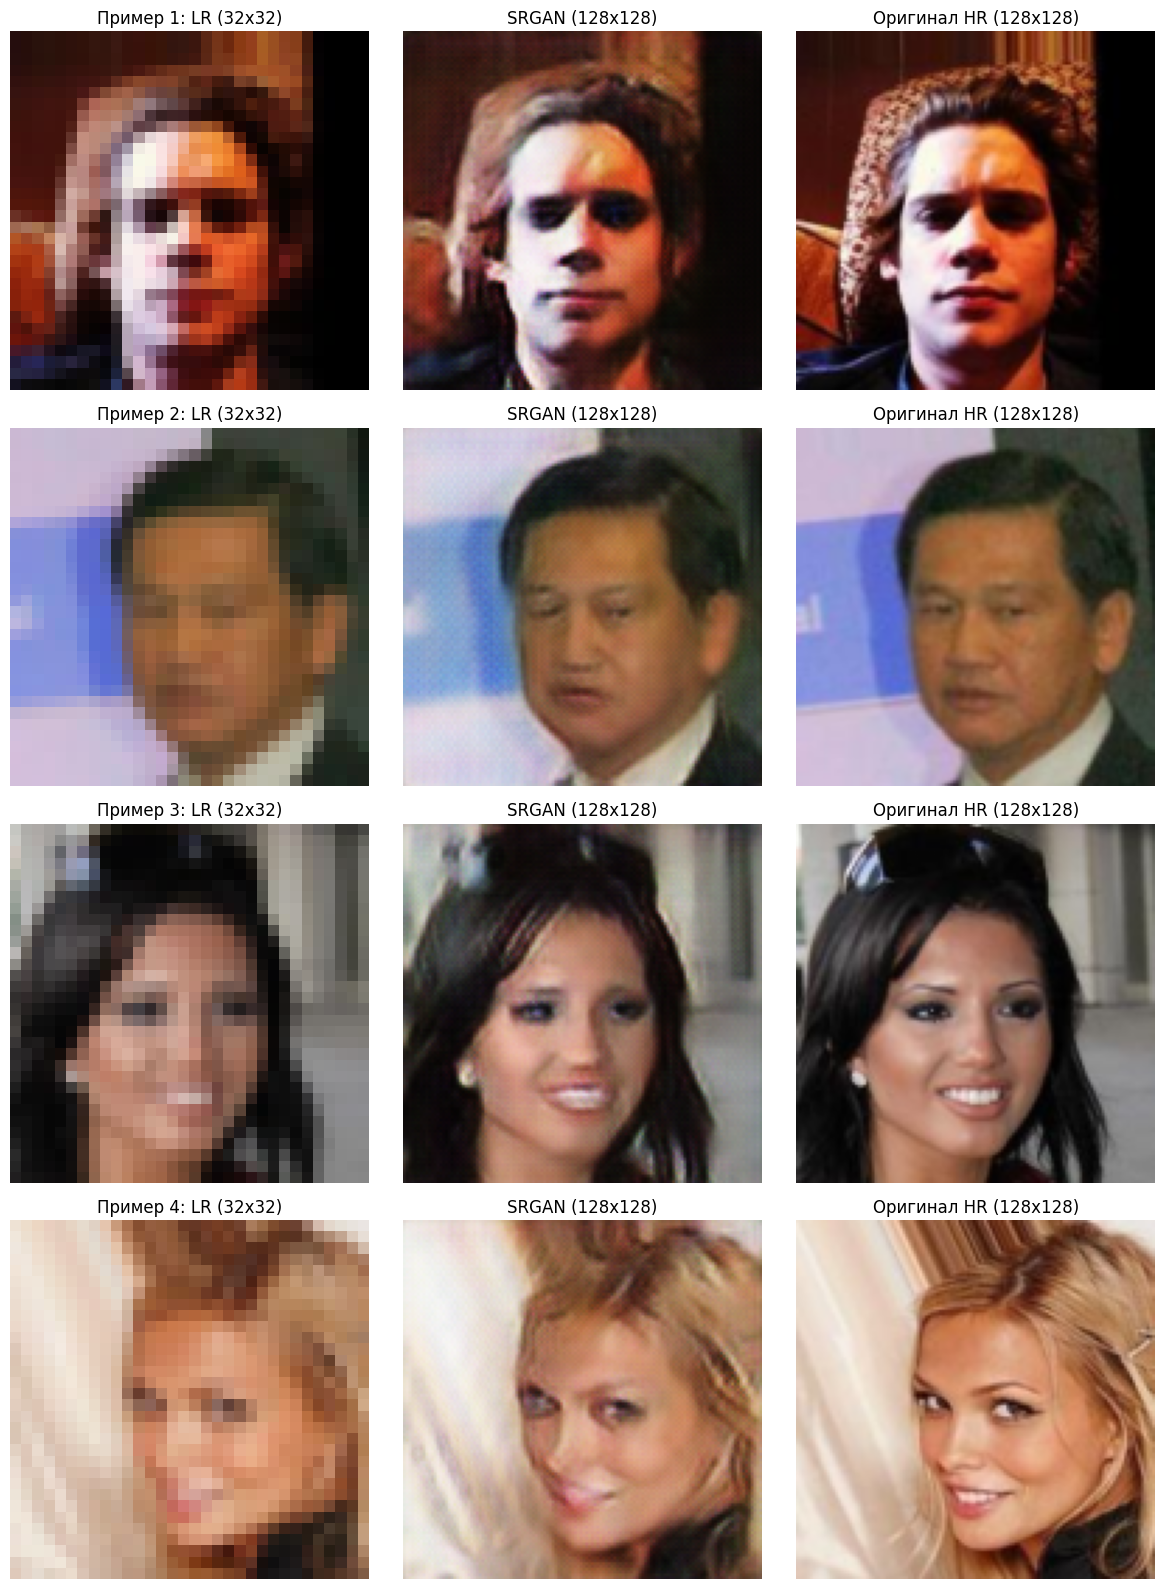

In [ ]:
def plot_multiple_results(lr_imgs, sr_imgs, hr_imgs, num_images=4):
    """Функция для отрисовки сетки изображений (несколько примеров)"""
    fig, axes = plt.subplots(num_images, 3, figsize=(12, 4 * num_images))

    for i in range(num_images):
        # Конвертация тензоров для отображения
        lr = lr_imgs[i].cpu().squeeze().permute(1, 2, 0).numpy()
        sr = sr_imgs[i].cpu().squeeze().permute(1, 2, 0).numpy()
        hr = hr_imgs[i].cpu().squeeze().permute(1, 2, 0).numpy()

        # Денормализация [-1, 1] -> [0, 1]
        lr = np.clip((lr + 1) / 2.0, 0, 1)
        sr = np.clip((sr + 1) / 2.0, 0, 1)
        hr = np.clip((hr + 1) / 2.0, 0, 1)

        if num_images == 1:
            axes = [axes]

        axes[i][0].imshow(lr)
        axes[i][0].set_title(f'Пример {i+1}: LR (32x32)')
        axes[i][0].axis('off')

        axes[i][1].imshow(sr)
        axes[i][1].set_title(f'SRGAN (128x128)')
        axes[i][1].axis('off')

        axes[i][2].imshow(hr)
        axes[i][2].set_title(f'Оригинал HR (128x128)')
        axes[i][2].axis('off')

    plt.tight_layout()
    plt.show()

generator.eval()
with torch.no_grad():
    sample_lr, sample_hr = next(iter(train_loader))
    sample_lr = sample_lr.to(device)
    sample_hr = sample_hr.to(device)
    sample_sr = generator(sample_lr)

plot_multiple_results(sample_lr, sample_sr, sample_hr, num_images=4)